In [40]:
import pandas as pd

df = pd.read_csv('../data/student_mental_health.csv')

print(f'data shape : {df.shape}')
df.head(5)
df.dtypes

# print(f'data columns : \n {df.columns}')
# columns = [
#     'Age', 
#     'Gender', 
#     'Year_of_Study', 
#     'Sleep_Hours',
#     'Study_Hours_Per_Week', 
#     'GPA', 
#     'Social_Media_Hours',
#     'Screen_Time_Hours', 
#     'Physical_Activity', 
#     'Financial_Stress',
#     'Family_Support', 
#     'Attendance_Rate', 
#     'Part_Time_Job', 
#     'Diet_Quality',
#     'Previous_Mental_Health_History', 
#     'Mental_Health_Risk'
# ]

data shape : (2000, 17)


Student_ID                            str
Age                                 int64
Gender                                str
Year_of_Study                       int64
Sleep_Hours                       float64
Study_Hours_Per_Week              float64
GPA                               float64
Social_Media_Hours                float64
Screen_Time_Hours                 float64
Physical_Activity                     str
Financial_Stress                  float64
Family_Support                    float64
Attendance_Rate                   float64
Part_Time_Job                         str
Diet_Quality                          str
Previous_Mental_Health_History        str
Mental_Health_Risk                    str
dtype: object

In [41]:
df.drop(columns=['Student_ID'], inplace=True)
print(f'duplicated rows : {df.duplicated().value_counts()}')
df.isna().sum()

duplicated rows : False    2000
Name: count, dtype: int64


Age                                0
Gender                             0
Year_of_Study                      0
Sleep_Hours                       62
Study_Hours_Per_Week               0
GPA                               38
Social_Media_Hours                58
Screen_Time_Hours                  0
Physical_Activity                  0
Financial_Stress                  91
Family_Support                    54
Attendance_Rate                   47
Part_Time_Job                      0
Diet_Quality                      69
Previous_Mental_Health_History     0
Mental_Health_Risk                 0
dtype: int64

In [42]:
num_cul = df.select_dtypes(include='number')
num_cul.agg(['min', 'max'])

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
min,17,1,3.3,2.4,1.50,2.1,3.3,1.4,1.7,54.4
max,29,5,10.0,38.3,3.66,10.0,14.0,10.0,9.9,100.0


In [43]:
count = (df['Screen_Time_Hours'] < df['Social_Media_Hours']).sum()
print(f'ilogique screen hours : {count}')

df[(df['Screen_Time_Hours'] < df['Social_Media_Hours'])].head(5)


ilogique screen hours : 37


,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
78,21,Male,2,5.3,17.0,2.54,5.0,4.9,Moderate,2.9,3.6,88.3,Yes,Good,Yes,High
168,20,Female,3,6.2,25.7,2.47,5.6,5.3,Moderate,4.6,7.5,88.7,Yes,Average,Yes,Medium
209,29,Female,4,6.5,22.1,3.02,7.5,7.3,Moderate,7.8,6.9,90.4,Yes,NaN,No,Low
278,21,Female,3,6.7,17.9,2.54,6.0,5.1,High,6.5,7.6,81.3,No,Good,Yes,Medium
382,17,Female,2,8.7,20.4,2.82,5.3,4.1,Low,3.8,8.8,90.5,Yes,Poor,Yes,Medium


In [44]:
condition = (df['Screen_Time_Hours'] < df['Social_Media_Hours'])
df.loc[condition, 'Screen_Time_Hours'] = df.loc[condition, 'Social_Media_Hours']

In [45]:
print(df['Mental_Health_Risk'].value_counts())

Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64


C:\Users\ycode\AppData\Local\Temp\ipykernel_22012\2267929420.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


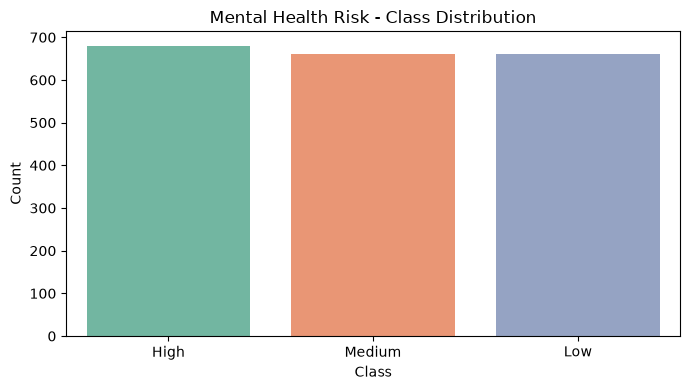

In [46]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 4))

sns.countplot(
    data=df,
    x='Mental_Health_Risk',
    order=df['Mental_Health_Risk'].value_counts().index,
    palette='Set2'
)

plt.title('Mental Health Risk - Class Distribution')
plt.xlabel('Class')
plt.ylabel('Count')

plt.tight_layout()
plt.show()

                                Age  Sleep_Hours  Study_Hours_Per_Week  \
Age                        1.000000    -0.010572             -0.007476   
Sleep_Hours               -0.010572     1.000000              0.032237   
Study_Hours_Per_Week      -0.007476     0.032237              1.000000   
GPA                        0.001437     0.246255              0.492501   
Social_Media_Hours        -0.007609     0.002183             -0.501178   
Screen_Time_Hours         -0.004946     0.020502             -0.338300   
Financial_Stress           0.004142     0.024435             -0.025538   
Family_Support            -0.010363     0.009997              0.041464   
Attendance_Rate           -0.009612     0.076609              0.138003   
Mental_Health_Risk_High    0.002260    -0.460444             -0.205249   
Mental_Health_Risk_Low    -0.006359     0.480487              0.208879   
Mental_Health_Risk_Medium  0.004082    -0.018228             -0.002104   

                                GPA  

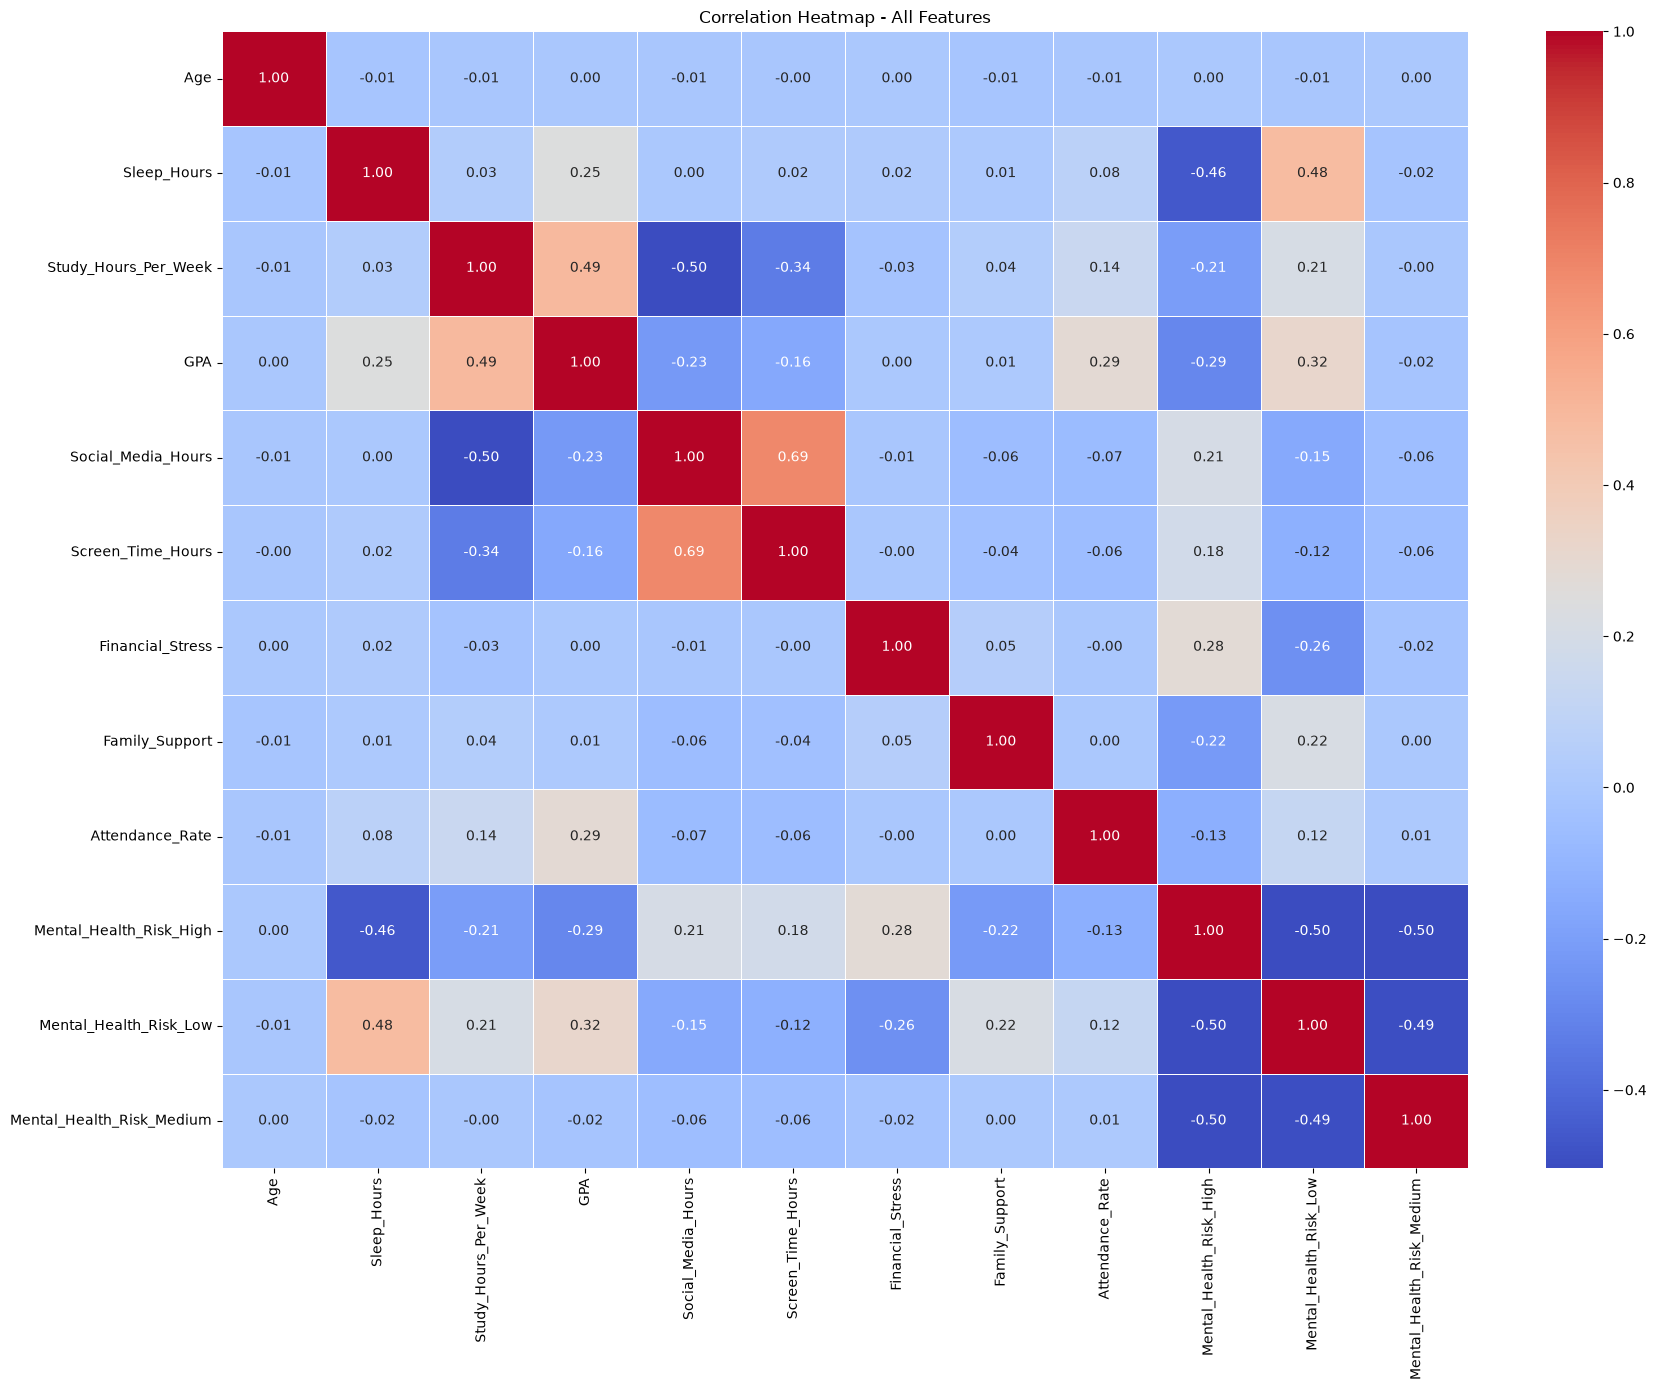

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

num_cols = [
    'Age',
    'Sleep_Hours',
    'Study_Hours_Per_Week', 
    'GPA', 
    'Social_Media_Hours',
    'Screen_Time_Hours', 
    'Financial_Stress',
    'Family_Support', 
    'Attendance_Rate',
]

# df_encoded = pd.get_dummies(df[num_cols], drop_first=False)
df_encoded = pd.get_dummies(df[num_cols + ['Mental_Health_Risk']], columns=['Mental_Health_Risk'], drop_first=False, dtype=int)
corr = df_encoded.corr()
print(corr)

plt.figure(figsize=(18, 14))
sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)
plt.title('Correlation Heatmap - All Features')
plt.tight_layout()
plt.show()

In [48]:
df.drop(columns=['Age'], inplace=True)

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns

catg_cols = [
    'Gender', 
    'Physical_Activity',
    'Part_Time_Job', 
    'Diet_Quality',
    'Previous_Mental_Health_History',
    'Year_of_Study'
]


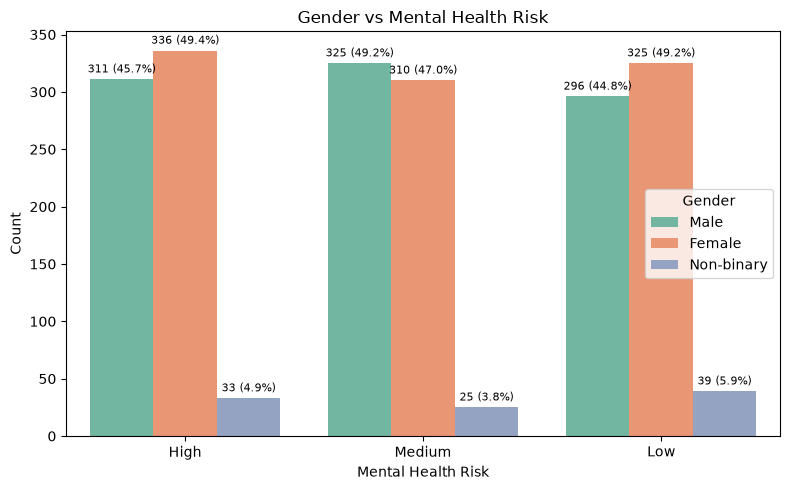

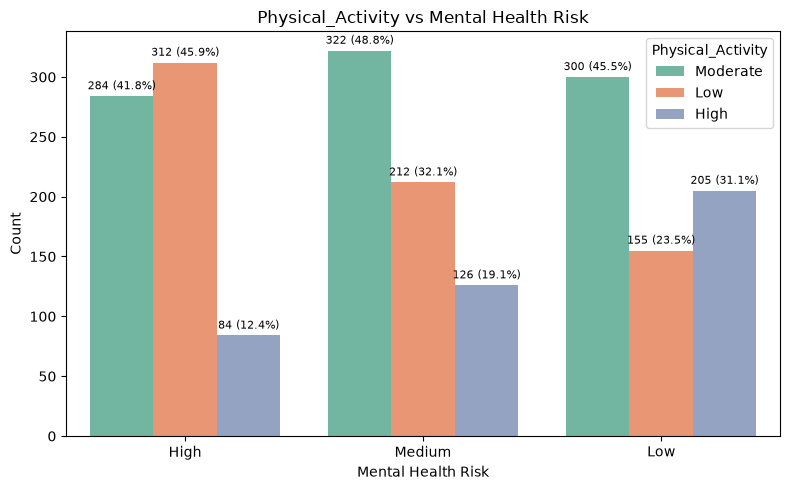

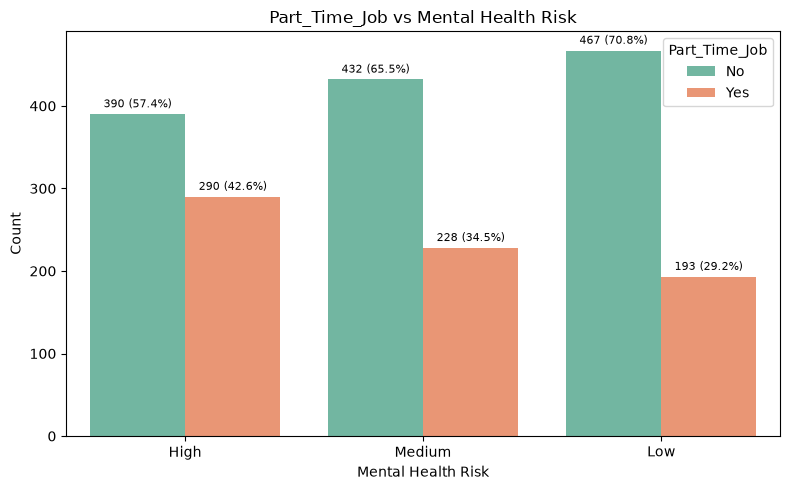

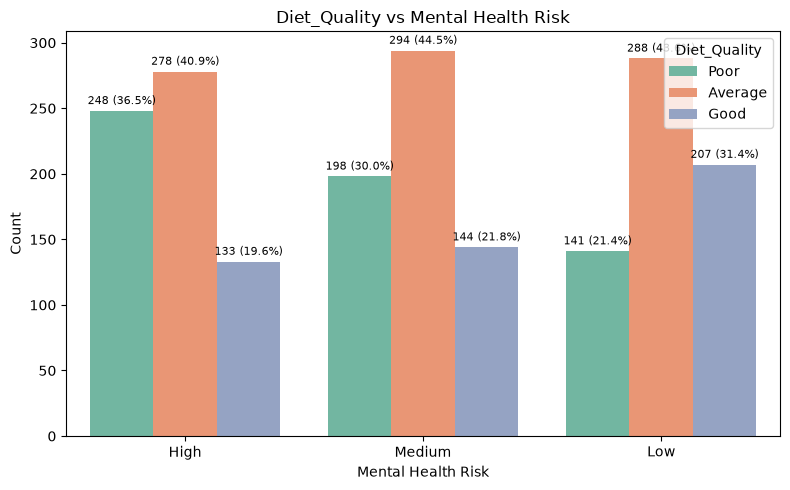

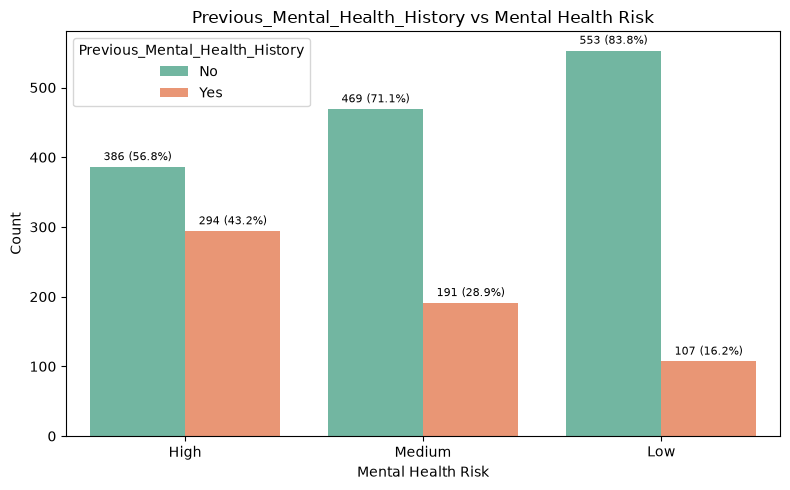

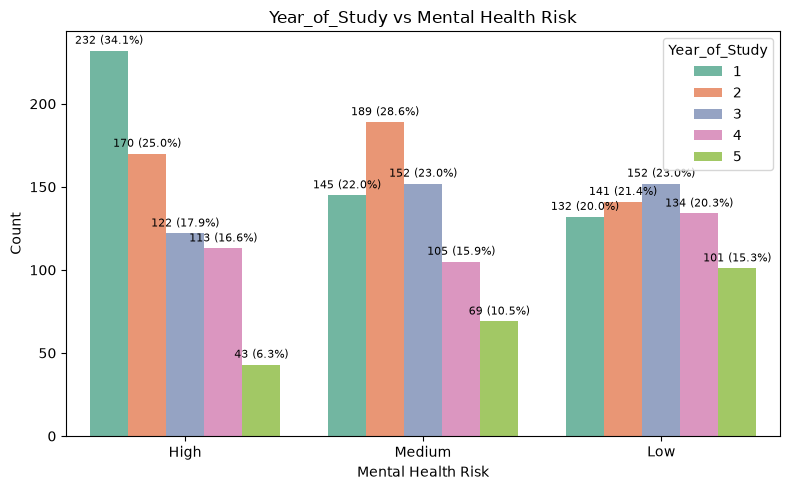

In [50]:
for col in catg_cols:
    plt.figure(figsize=(8, 5))

    ax = sns.countplot(
        data=df,
        x='Mental_Health_Risk',
        hue=col,
        palette='Set2'
    )

    totals = df['Mental_Health_Risk'].value_counts()

    for container in ax.containers:
        labels = []

        for i, bar in enumerate(container):
            count = bar.get_height()
            risk = ax.get_xticklabels()[i].get_text()
            percentage = (count / totals[risk]) * 100 if totals[risk] else 0

            labels.append(f'{count:.0f} ({percentage:.1f}%)')

        ax.bar_label(container, labels=labels, padding=3, fontsize=8)

    plt.title(f'{col} vs Mental Health Risk')
    plt.xlabel('Mental Health Risk')
    plt.ylabel('Count')
    plt.legend(title=col)
    plt.tight_layout()
    plt.show()

In [51]:
target_cols = [
    'Mental_Health_Risk_High',
    'Mental_Health_Risk_Medium',
    'Mental_Health_Risk_Low'
]

target_corr = corr[target_cols].drop(target_cols, errors='ignore')

strongest = target_corr.abs().max(axis=1).sort_values(ascending=False)

print(strongest.head(10))

Sleep_Hours             0.480487
GPA                     0.317516
Financial_Stress        0.281580
Family_Support          0.218369
Study_Hours_Per_Week    0.208879
Social_Media_Hours      0.206940
Screen_Time_Hours       0.179481
Attendance_Rate         0.130791
Age                     0.006359
dtype: float64


In [52]:
#  searching for outliers : 
df.columns.max()

'Year_of_Study'

## Fill Missing Data

In [53]:
from sklearn.preprocessing import OrdinalEncoder
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
import pandas as pd

col_num = df.select_dtypes(exclude=['object', 'string']).columns
col_catg = df.select_dtypes(include=['object', 'string']).columns

encoder = OrdinalEncoder()
df[col_catg] = encoder.fit_transform(df[col_catg])

imputer = IterativeImputer(random_state=42, max_iter=10)
df_imputed = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)

df_imputed[col_catg] = df_imputed[col_catg].round().astype(int)
df_imputed[col_catg] = encoder.inverse_transform(df_imputed[col_catg])
df_imputed['Year_of_Study'] = df_imputed['Year_of_Study'].astype('int64')

df = df_imputed
df.to_csv('../data/cleaned_ds.csv', index=False)
print('data saved succefully!!!!!!!!!!!!!!!!!!!!')
df.isna().sum()

data saved succefully!!!!!!!!!!!!!!!!!!!!


Gender                            0
Year_of_Study                     0
Sleep_Hours                       0
Study_Hours_Per_Week              0
GPA                               0
Social_Media_Hours                0
Screen_Time_Hours                 0
Physical_Activity                 0
Financial_Stress                  0
Family_Support                    0
Attendance_Rate                   0
Part_Time_Job                     0
Diet_Quality                      0
Previous_Mental_Health_History    0
Mental_Health_Risk                0
dtype: int64